In [ ]:
# 9. Develop a CNN-based classification model using the Sign Language 
# MNIST dataset. Predict alphabet labels for test images and display the 
# actual and predicted alphabet for any five test samples. 

In [1]:
# Import required libraries

import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

In [2]:
# Load training and testing datasets

train_data = pd.read_csv('sign_mnist_train.csv')
test_data = pd.read_csv('sign_mnist_test.csv')

# Display dataset shapes

print("Training Data:", train_data.shape)
print("Testing Data:", test_data.shape)

Training Data: (27455, 785)
Testing Data: (7172, 785)


In [3]:
# Separate images and their labels

X_train = train_data.drop('label', axis=1).values
y_train = train_data['label'].values

X_test = test_data.drop('label', axis=1).values
y_test = test_data['label'].values

In [4]:
# Convert original labels into consecutive class numbers

classes = np.sort(np.unique(y_train))

label_map = {label: i for i, label in enumerate(classes)}

y_train = np.array([label_map[x] for x in y_train])
y_test = np.array([label_map[x] for x in y_test])

# Create alphabet names (excluding J and Z)

label_names = [chr(i + 65) for i in range(26) if i not in [9, 25]]

print("Total Classes:", len(label_names))

Total Classes: 24


In [5]:
# Normalize pixel values between 0 and 1

X_train = X_train.astype('float32') / 255.0
X_test = X_test.astype('float32') / 255.0

# Reshape images into 28x28x1 format

X_train = X_train.reshape(-1, 28, 28, 1)
X_test = X_test.reshape(-1, 28, 28, 1)

print("Training Shape:", X_train.shape)
print("Testing Shape:", X_test.shape)

Training Shape: (27455, 28, 28, 1)
Testing Shape: (7172, 28, 28, 1)


In [6]:
# Create CNN model

model = tf.keras.Sequential([

    # Input layer
    tf.keras.layers.Input(shape=(28, 28, 1)),

    # First convolution layer
    tf.keras.layers.Conv2D(32, (3,3), activation='relu'),

    # First pooling layer
    tf.keras.layers.MaxPooling2D((2,2)),

    # Second convolution layer
    tf.keras.layers.Conv2D(64, (3,3), activation='relu'),

    # Second pooling layer
    tf.keras.layers.MaxPooling2D((2,2)),

    # Convert feature maps into 1D
    tf.keras.layers.Flatten(),

    # Fully connected layer
    tf.keras.layers.Dense(128, activation='relu'),

    # Output layer for 24 classes
    tf.keras.layers.Dense(24, activation='softmax')
])

# Display model architecture
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 26, 26, 32)          │             320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 13, 13, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 11, 11, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 5, 5, 64)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 1600)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │         204,928 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 24)                  │           3,096 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 226,840 (886.09 KB)

 Trainable params: 226,840 (886.09 KB)

 Non-trainable params: 0 (0.00 B)

In [7]:
# Compile the CNN model

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

print("Model compiled successfully!")

Model compiled successfully!


In [8]:
# Train the CNN model

model.fit(
    X_train,
    y_train,
    epochs=10,
    batch_size=128
)

Epoch 1/10
215/215 ━━━━━━━━━━━━━━━━━━━━ 6s 21ms/step - accuracy: 0.5564 - loss: 1.5531
Epoch 2/10
215/215 ━━━━━━━━━━━━━━━━━━━━ 4s 18ms/step - accuracy: 0.9125 - loss: 0.3177
Epoch 3/10
215/215 ━━━━━━━━━━━━━━━━━━━━ 4s 18ms/step - accuracy: 0.9865 - loss: 0.0851
Epoch 4/10
215/215 ━━━━━━━━━━━━━━━━━━━━ 4s 20ms/step - accuracy: 0.9979 - loss: 0.0283
Epoch 5/10
215/215 ━━━━━━━━━━━━━━━━━━━━ 5s 21ms/step - accuracy: 0.9992 - loss: 0.0133
Epoch 6/10
215/215 ━━━━━━━━━━━━━━━━━━━━ 4s 19ms/step - accuracy: 0.9999 - loss: 0.0075
Epoch 7/10
215/215 ━━━━━━━━━━━━━━━━━━━━ 5s 22ms/step - accuracy: 0.9999 - loss: 0.0045
Epoch 8/10
215/215 ━━━━━━━━━━━━━━━━━━━━ 4s 20ms/step - accuracy: 1.0000 - loss: 0.0031
Epoch 9/10
215/215 ━━━━━━━━━━━━━━━━━━━━ 5s 22ms/step - accuracy: 1.0000 - loss: 0.0021
Epoch 10/10
215/215 ━━━━━━━━━━━━━━━━━━━━ 4s 20ms/step - accuracy: 1.0000 - loss: 0.0015


In [9]:
# Evaluate model using testing data

test_loss, test_accuracy = model.evaluate(X_test, y_test)

print("Testing Accuracy: {:.2f}%".format(test_accuracy * 100))

225/225 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.9035 - loss: 0.4352
Testing Accuracy: 90.35%


In [10]:
# Predict labels for test images

predictions = model.predict(X_test)

# Get class with highest probability

predicted_labels = np.argmax(predictions, axis=1)

print("Predictions completed successfully!")

225/225 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step
Predictions completed successfully!


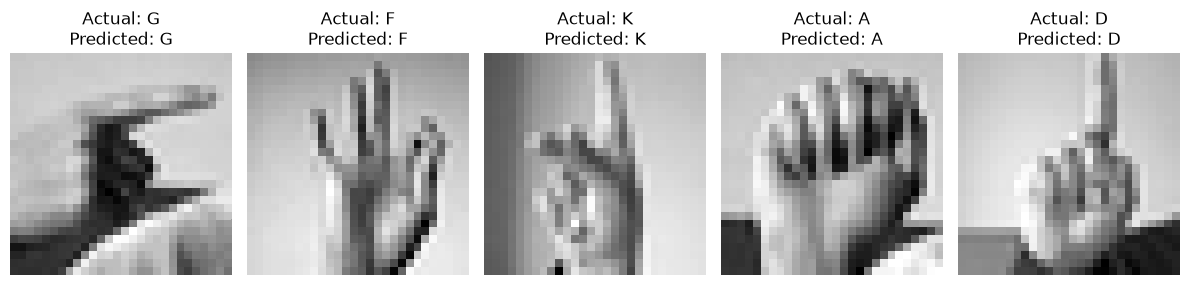

In [11]:
# Display five test images with actual and predicted labels

plt.figure(figsize=(12, 5))

for i in range(5):

    # Get actual and predicted alphabets
    actual = label_names[y_test[i]]
    predicted = label_names[predicted_labels[i]]

    # Display image
    plt.subplot(1, 5, i+1)
    plt.imshow(X_test[i].reshape(28, 28), cmap='gray')

    # Display labels
    plt.title("Actual: " + actual + "\nPredicted: " + predicted)
    plt.axis('off')

plt.tight_layout()
plt.show()